In [1]:
from pyprojroot import here
PROJECT_ROOT = here()
DATASET_DIR = PROJECT_ROOT / "Synthesized_Dataset"
MODEL_DIR = PROJECT_ROOT / "models"
IR_DIR = PROJECT_ROOT / "Pz and Sz"
print(PROJECT_ROOT)
print(DATASET_DIR)
print(MODEL_DIR)

/home/kobarin/Projects/Anc/GFANC-custom
/home/kobarin/Projects/Anc/GFANC-custom/Synthesized_Dataset
/home/kobarin/Projects/Anc/GFANC-custom/models


In [5]:
from gfanc.data.DataSet_construction import MySoundGenerator

fs = 16000
sub_folders = {"Training_data": 1000, "Validate_data": 1000, "Testing_data": 1000}
time = 10
for sub_folder, num in sub_folders.items():
    MSG = MySoundGenerator(fs, DATASET_DIR/sub_folder, time)
    for i in range(num):
        MSG._construct_()
    print(f"finished: {sub_folder}, {num}")

finished: Training_data, 1000
finished: Validate_data, 1000
finished: Testing_data, 1000


In [3]:
from gfanc.data.Automatic_Hard_Label_Subfilters_batch import Automatic_label
sub_folders = {"Training_data": 1000, "Validate_data": 1000, "Testing_data": 1000}
sufix = ".wav"
threshould = 0.5
BATCH_SIZE = 1000 * 10
num_workers = 4

=====================Start labeling ============================
The total file numer is 1000
<<===This program used cpu====>>


/home/kobarin/miniforge3/envs/anc/lib/python3.12/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
[========================================================================] 100%


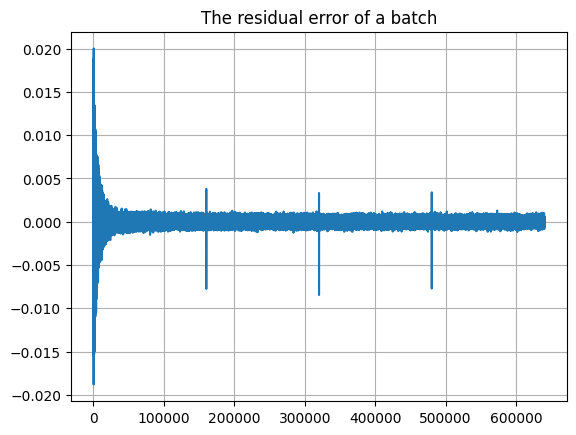

[========================================================================] 100%


=======================End labeling ============================
=====================Start labeling ============================
The total file numer is 1000
<<===This program used cpu====>>


/home/kobarin/miniforge3/envs/anc/lib/python3.12/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
[========================================================================] 100%


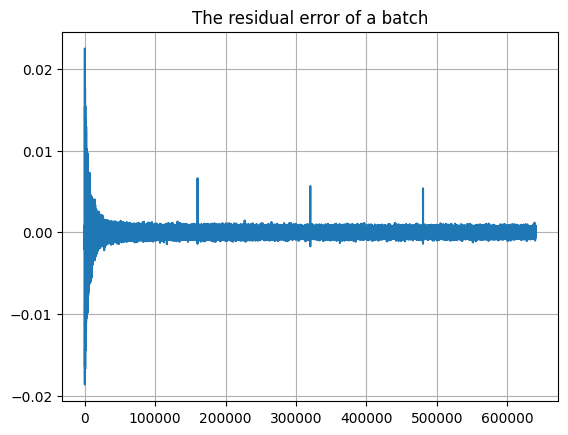

[========================================================================] 100%


=======================End labeling ============================
=====================Start labeling ============================
The total file numer is 1000
<<===This program used cpu====>>


/home/kobarin/miniforge3/envs/anc/lib/python3.12/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
[========================================================================] 100%


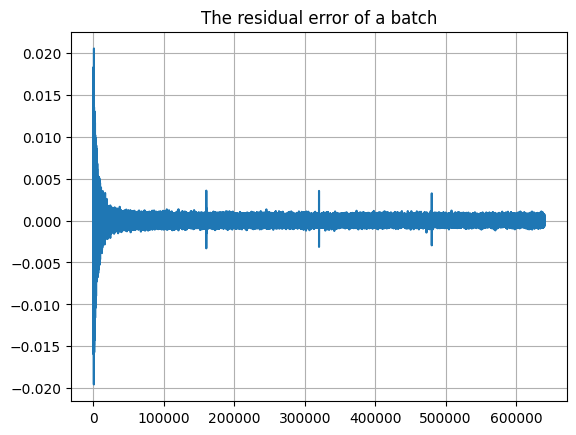

[========================================================================] 100%


=======================End labeling ============================
=====================Start labeling ============================
The total file numer is 1000
<<===This program used cpu====>>


/home/kobarin/miniforge3/envs/anc/lib/python3.12/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
[========================================================================] 100%


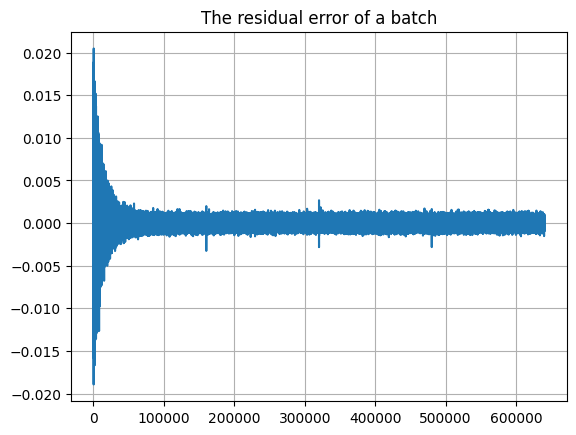

[========================================================================] 100%


=======================End labeling ============================
=====================Start labeling ============================
The total file numer is 1000
<<===This program used cpu====>>


/home/kobarin/miniforge3/envs/anc/lib/python3.12/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
[========================================================================] 100%


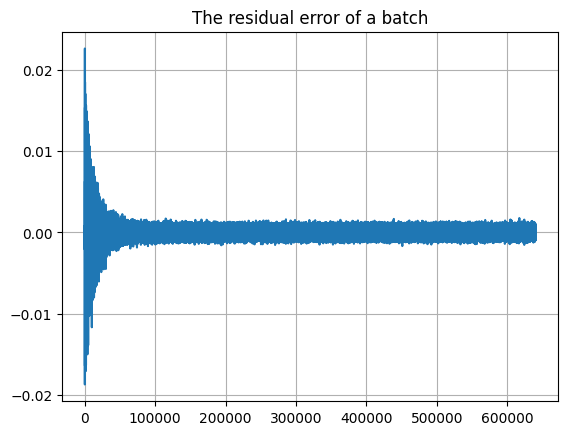

[========================================================================] 100%


=======================End labeling ============================
=====================Start labeling ============================
The total file numer is 1000
<<===This program used cpu====>>


/home/kobarin/miniforge3/envs/anc/lib/python3.12/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
[========================================================================] 100%


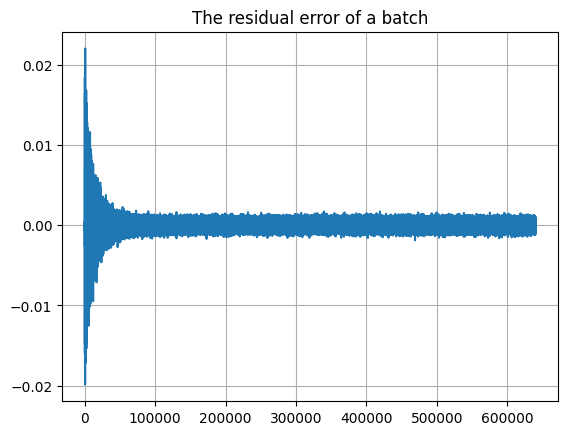

[========================================================================] 100%


=======================End labeling ============================
=====================Start labeling ============================
The total file numer is 1000
<<===This program used cpu====>>


/home/kobarin/miniforge3/envs/anc/lib/python3.12/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
[========================================================================] 100%


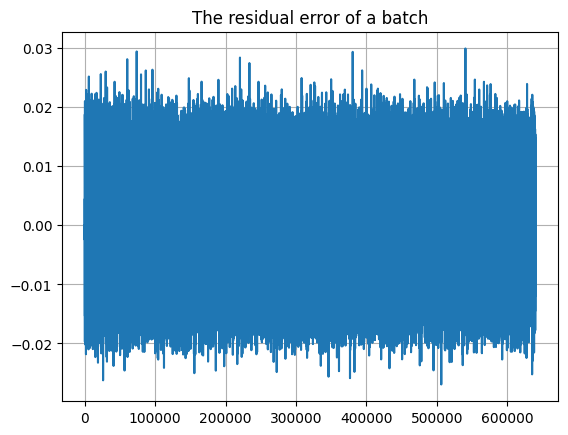

[========================================================================] 100%


=======================End labeling ============================
=====================Start labeling ============================
The total file numer is 1000
<<===This program used cpu====>>


/home/kobarin/miniforge3/envs/anc/lib/python3.12/site-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


KeyboardInterrupt: 

In [6]:
delays = [-25, 0, 5]
for delay in delays:
    subfilters = "Pretrained_Sub_Control_filters_delay_" + str(delay) + ".mat"
    path_mat = MODEL_DIR / subfilters
    Index_file = "Hard_Index_delay_" + str(delay) + ".csv"
    subfolder = "Secondary_path_delay_" + str(delay) + "samples"
    #BATCH_SIZE: 1000*10 -> 5000MiB
    for sub_folder, _ in sub_folders.items():
        folder_path = DATASET_DIR / sub_folder
        label = Automatic_label(sufix, folder_path, path_mat, Index_file, threshould, folder=IR_DIR, subfolder=subfolder, BATCH_SIZE=BATCH_SIZE, num_workers=num_workers,)
        label.label()